# 02 · N-tuple network

TD(0) afterstate learning with the 4×6-tuple network (`src/ntuple/`). Long runs are started
from the terminal (see `TRAINING.md`); this notebook launches short runs, plots the CSV logs,
inspects checkpoints and evaluates them.

In [1]:
%load_ext autoreload
%autoreload 2

import platform

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display

from game import engine as E
from ntuple import evaluate as V
from ntuple import expectimax as X
from ntuple import model as M
from ntuple import train as T

assert platform.machine() == "arm64", platform.machine()
print("logs:", T.LOG_ROOT, "\ncheckpoints:", T.CHECKPOINT_ROOT)

logs: /Users/ardacakil/Desktop/2048-bot/logs 
checkpoints: /Users/ardacakil/Desktop/2048-bot/checkpoints


## Check the overnight runs

Run these two cells in the morning (after the imports cell). They read
`logs/overnight-*.csv`, which the runs append to every 1,000 games, so they also work while
training is still going.

In [2]:
OVERNIGHT_RUNS = {"overnight-a01": 0.1, "overnight-a005": 0.05, "overnight-a0025": 0.025}

logs = {}
for run in OVERNIGHT_RUNS:
    path = T.LOG_ROOT / f"{run}.csv"
    if not path.exists():
        print(f"{run:16s} no log yet")
        continue
    logs[run] = log = T.read_log(path)
    last, recent = log.iloc[-1], log.tail(20)
    print(f"{run:16s} {int(last.games):>10,} games  {last.elapsed_s / 3600:5.2f} h  "
          f"avg score (last 20k games) {recent.avg_score.mean():>9,.0f}  "
          f"2048 {recent.reach_2048.mean():5.1f}%  8192 {recent.reach_8192.mean():5.1f}%  "
          f"{last.games_per_s:>5,.0f} games/s")

overnight-a01    no log yet
overnight-a005   no log yet
overnight-a0025  no log yet


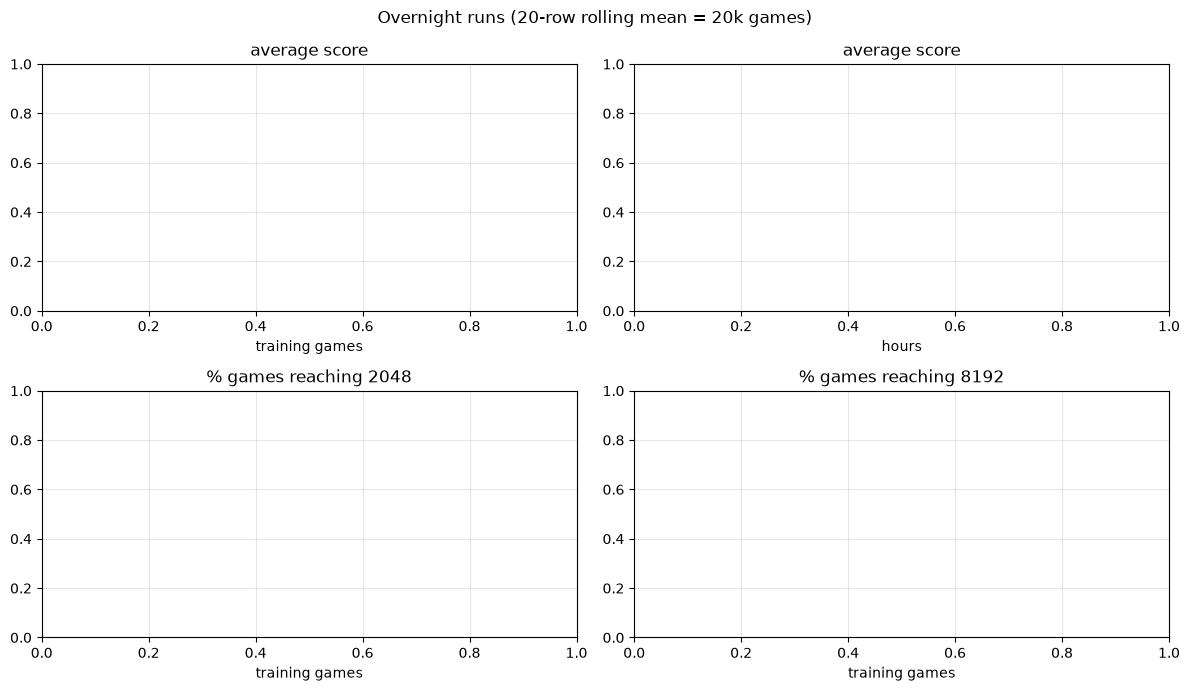

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for run, log in logs.items():
    label = f"{run} (α={OVERNIGHT_RUNS[run]})"
    smooth = log.set_index("games")[["avg_score", "reach_2048", "reach_8192"]].rolling(20, min_periods=1).mean()
    hours = log["elapsed_s"].to_numpy() / 3600
    axes[0, 0].plot(smooth.index, smooth.avg_score, label=label)
    axes[0, 1].plot(hours, smooth.avg_score.to_numpy(), label=label)
    axes[1, 0].plot(smooth.index, smooth.reach_2048, label=label)
    axes[1, 1].plot(smooth.index, smooth.reach_8192, label=label)
axes[0, 0].set(title="average score", xlabel="training games")
axes[0, 1].set(title="average score", xlabel="hours")
axes[1, 0].set(title="% games reaching 2048", xlabel="training games")
axes[1, 1].set(title="% games reaching 8192", xlabel="training games")
for ax in axes.flat:
    ax.grid(alpha=0.3)
if logs:
    axes[0, 0].legend()
plt.suptitle("Overnight runs (20-row rolling mean = 20k games)")
plt.tight_layout()
plt.show()

## Launch a short run

5,000 games, about 2 seconds. Trains in-process (Ctrl+C / the stop button saves a checkpoint and returns). Skipped if the
run already exists; delete `checkpoints/nb-demo` and `logs/nb-demo.csv` to start over.

In [4]:
RUN = "nb-demo"
if (T.CHECKPOINT_ROOT / RUN / "meta.json").exists():
    print(f"{RUN} already trained; resume with T.train(resume_run=RUN, games=...)")
else:
    T.train(T.Config(run=RUN, games=5_000, alpha=0.1, seed=0))

nb-demo already trained; resume with T.train(resume_run=RUN, games=...)


## Learning curves

Every run in `logs/`. Left: per game; right: per wall-clock second, which is what matters
when comparing update orders.

['calib-backward', 'calib-online', 'nb-demo', 'smoke-backward', 'smoke-online']


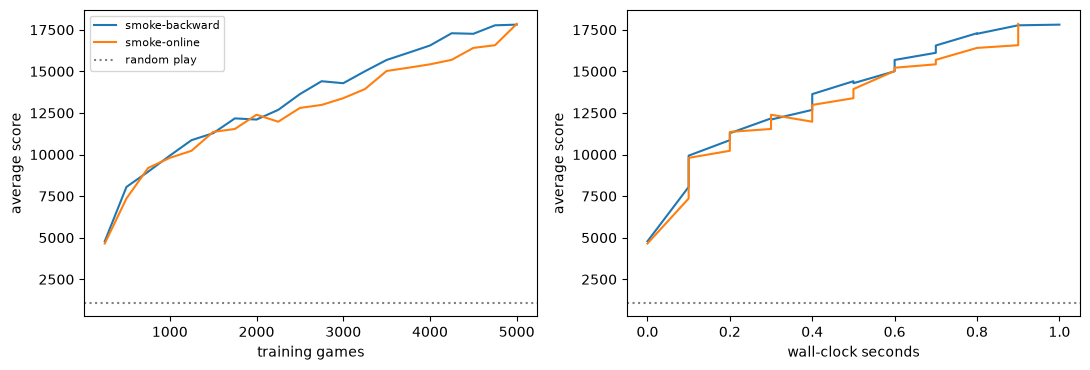

In [5]:
def plot_runs(runs, smooth=1):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
    for run in runs:
        log = T.read_log(T.LOG_ROOT / f"{run}.csv")
        y = log["avg_score"].rolling(smooth, min_periods=1).mean()
        a1.plot(log["games"], y, label=run)
        a2.plot(log["elapsed_s"], y, label=run)
    a1.axhline(1100, color="gray", ls=":", label="random play")
    a2.axhline(1100, color="gray", ls=":")
    a1.set(xlabel="training games", ylabel="average score")
    a2.set(xlabel="wall-clock seconds", ylabel="average score")
    a1.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

all_runs = sorted(p.stem for p in T.LOG_ROOT.glob("*.csv"))
print(all_runs)
plot_runs([r for r in all_runs if r.startswith("smoke-")])

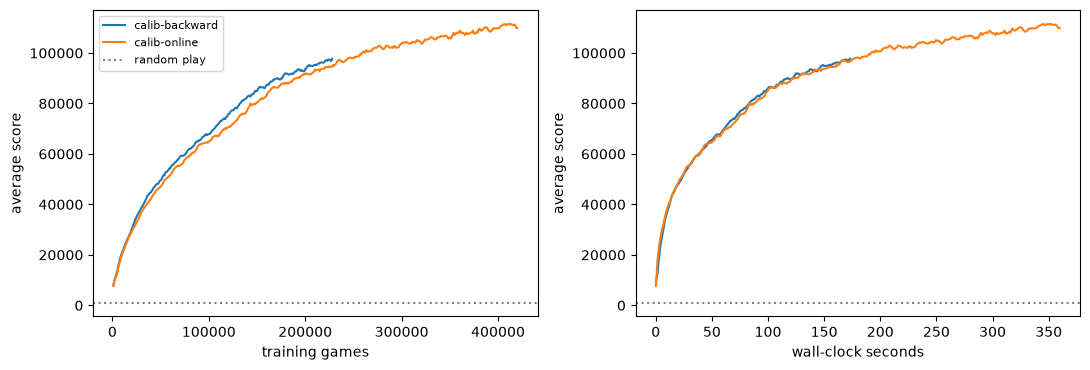

In [6]:
plot_runs([r for r in all_runs if r.startswith("calib-")], smooth=5)

## Load a checkpoint

In [7]:
CKPT = T.CHECKPOINT_ROOT / RUN  # e.g. T.CHECKPOINT_ROOT / "overnight-a01"
W, meta = T.load_checkpoint(CKPT, mmap=True)
print({k: meta[k] for k in ("games_done", "total_moves", "elapsed_s", "weights_file")})
print(meta["config"])
print(f"non-zero weights: {np.count_nonzero(W) / W.size:.1%}")

{'games_done': 5000, 'total_moves': 3640152, 'elapsed_s': 0.7386673341970891, 'weights_file': 'weights-0000005000.npy'}
{'run': 'nb-demo', 'games': 5000, 'alpha': 0.1, 'seed': 0, 'update_order': 'online', 'checkpoint_every': 20000, 'checkpoint_minutes': 20.0, 'log_every': 1000, 'decay_factor': 1.0, 'decay_every': 0, 'keep_every': 0}
non-zero weights: 2.4%


## Watch a game step by step

Expectimax at depth 1. For every position the table shows `reward + value` per legal move
(depth-1 search value); drag the slider to step through the game.

In [8]:
def record_game(W, depth=1, seed=0):
    ex = X.Expectimax(W, depth=depth)
    rng = E.make_rng(seed)
    board, score, steps = E.new_game(rng), 0, []
    while True:
        options = {}
        for a in range(4):
            after, r = E.move(board, a)
            if after != board:
                options[E.ACTION_NAMES[a]] = r + X.chance_value(W, after, depth, 1.0, ex.prune, *ex.table, True)
        a, _ = ex.best_move(board)
        steps.append((board, score, options, a))
        if a < 0:
            return steps
        after, r = E.move(board, a)
        score += r
        board = E.spawn_tile(after, rng)

steps = record_game(W, depth=1, seed=3)
final = steps[-1]
print(f"{len(steps) - 1} moves, score {final[1]:,}, max tile {1 << E.max_tile(final[0])}")

def show(step=0):
    board, score, options, a = steps[step]
    vals = "\n".join(f"  {k:>5}: {v:12,.1f}{'  <-' if E.ACTION_NAMES[a] == k else ''}" for k, v in options.items())
    nxt = E.ACTION_NAMES[a] if a >= 0 else "game over"
    display(HTML(f"<pre>move {step}   score {score:,}   next: {nxt}\n{E.format_board(board)}\n{vals}</pre>"))

widgets.interact(show, step=widgets.IntSlider(0, 0, len(steps) - 1, 1, layout={"width": "600px"}));

836 moves, score 14,196, max tile 1024


interactive(children=(IntSlider(value=0, description='step', layout=Layout(width='600px'), max=836), Output())…

## Evaluation

Greedy (depth 0, the training policy) and expectimax depth 2, in parallel worker processes.

In [9]:
greedy, greedy_games = V.evaluate(CKPT, games=200, depth=0)

  20/200 games, 0.5 s


  40/200 games, 0.5 s


  60/200 games, 0.5 s


  80/200 games, 0.5 s


  100/200 games, 0.5 s


...

  140/200 games, 0.5 s


  160/200 games, 0.5 s


  180/200 games, 0.5 s


  200/200 games, 0.5 s


/Users/ardacakil/Desktop/2048-bot/checkpoints/nb-demo  depth 0  200 games  (8 workers, 0.5 s)
  score   avg 14,662  ± 7,060   median 14,000   max 45,928
  reach   2048: 13.0%   4096: 0.5%   8192: 0.0%   16384: 0.0%
  max tile 4096: 0.5%  2048: 12.5%  1024: 55.5%  512: 26.5%  256: 5.0%
  time    0.001 ms/move (per worker)


In [10]:
deep, deep_games = V.evaluate(CKPT, games=48, depth=2)

  4/48 games, 0.9 s


  8/48 games, 1.1 s


  12/48 games, 1.3 s


  16/48 games, 1.6 s


  20/48 games, 1.8 s


...

  36/48 games, 2.7 s


  40/48 games, 2.9 s


  44/48 games, 3.2 s


  48/48 games, 3.5 s


/Users/ardacakil/Desktop/2048-bot/checkpoints/nb-demo  depth 2  48 games  (8 workers, 3.5 s)
  score   avg 38,852  ± 15,124   median 35,540   max 78,816
  reach   2048: 89.6%   4096: 25.0%   8192: 0.0%   16384: 0.0%
  max tile 4096: 25.0%  2048: 64.6%  1024: 10.4%
  time    0.242 ms/move (per worker)


In [11]:
pd.DataFrame({
    "greedy": {k: greedy[k] for k in ("avg_score", "median_score", "reach_2048", "reach_4096", "reach_8192", "ms_per_move")},
    "depth 2": {k: deep[k] for k in ("avg_score", "median_score", "reach_2048", "reach_4096", "reach_8192", "ms_per_move")},
}).round(3)

,greedy,depth 2
avg_score,14662.000,38851.667
median_score,14000.000,35540.000
reach_2048,13.000,89.583
reach_4096,0.500,25.000
reach_8192,0.000,0.000
ms_per_move,0.001,0.242
